# Week 1 - Self-Driving Car using Deep Learning: Problem & Data Understanding

**Objective:** Build a CNN that predicts the **steering angle** of a car from the image taken by its front camera, and train/evaluate it on a real driving dataset.

## What you will learn this week
* **a. Problem definition** - self-driving steering is a *regression* problem: input = road image, output = one continuous number (steering angle in [-1, 1]).
* **b. Data understanding** - the simulator records a `driving_log.csv` with three camera images per moment (center / left / right) plus steering, throttle, reverse and speed.

## Big picture of the 4-week experiment
| Week | Content |
|---|---|
| 1 | Problem definition, loading the dataset |
| 2 | Cleaning, steering-angle EDA, balancing, train/test split, mean baseline |
| 3 | Image pre-processing, batch generator, NVIDIA CNN architecture |
| 4 | Training, evaluation, visualising predictions, saving the model |

## Step 1 - Imports
We bring in the libraries used throughout the experiment:
* `numpy`, `pandas` - numerical arrays and tables
* `matplotlib` - plots and image display
* `cv2` (OpenCV) - image processing (colour conversion, blur, resize)
* `sklearn` - shuffling and train/test splitting
* `tensorflow.keras` - building and training the CNN

The record uses `!pip install ...` for Colab; here the packages are already installed. I also fix random seeds so results are repeatable.

In [1]:
import os, random, ntpath, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Dense, MaxPooling2D, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

random.seed(0); np.random.seed(0); tf.random.set_seed(0)

## Step 2 - Get the dataset
The record clones `https://github.com/Aman-py/data.git`. That repository holds a `driving_log.csv` and an `IMG/` folder of simulator screenshots.
The cell below clones it only if it is not already on disk (into `data/selfdrive`).

In [2]:
datadir = "data/selfdrive"
if not os.path.exists(os.path.join(datadir, "driving_log.csv")):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Aman-py/data.git", datadir], check=True)
print("Dataset folder ready:", os.path.exists(datadir))
print("Images in IMG/:", len(os.listdir(os.path.join(datadir, "IMG"))))

Dataset folder ready: True
Images in IMG/: 21777


## Step 3 - Read the driving log
The CSV has **no header row**, so we pass `names=columns` to give each column a name:

| Column | Meaning |
|---|---|
| `center`, `left`, `right` | file path of the image from each of the three cameras |
| `steering` | steering angle, -1 (full left) to +1 (full right) - **our target** |
| `throttle`, `reverse`, `speed` | other driving signals (not used here) |

In [3]:
columns = ["center", "left", "right", "steering", "throttle", "reverse", "speed"]
dataset = pd.read_csv(os.path.join(datadir, "driving_log.csv"), names=columns)
print("Number of samples:", len(dataset))
print("Columns:", list(dataset.columns))
dataset.head()

Number of samples: 7259
Columns: ['center', 'left', 'right', 'steering', 'throttle', 'reverse', 'speed']


,center,left,right,steering,throttle,reverse,speed
0,/home/aman-py/Desktop/Self-Driving-Car/data/IM...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,0.0,0.0,0.0,0.000078
1,/home/aman-py/Desktop/Self-Driving-Car/data/IM...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,0.0,0.0,0.0,0.000078
2,/home/aman-py/Desktop/Self-Driving-Car/data/IM...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,0.0,0.0,0.0,0.000079
3,/home/aman-py/Desktop/Self-Driving-Car/data/IM...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,0.0,0.0,0.0,0.000078
4,/home/aman-py/Desktop/Self-Driving-Car/data/IM...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,/home/aman-py/Desktop/Self-Driving-Car/data/I...,0.0,0.0,0.0,0.000079


## Step 4 - Quick look at the data
`describe()` summarises the numeric columns. Look at the `steering` row: the median is ~0, i.e. most of the time the car just drives straight. This imbalance is the main data problem we handle in Week 2.

In [4]:
print(dataset[["steering", "throttle", "speed"]].describe().round(4))
print("\nShare of frames with |steering| < 0.04:", round((dataset["steering"].abs() < 0.04).mean() * 100, 1), "%")

        steering   throttle      speed
count  7259.0000  7259.0000  7259.0000
mean     -0.0177     0.2831    19.9303
std       0.1832     0.3994     7.6456
min      -1.0000     0.0000     0.0001
25%       0.0000     0.0000    14.0720
50%       0.0000     0.0000    19.5122
75%       0.0000     0.5466    27.1582
max       1.0000     1.0000    30.6142

Share of frames with |steering| < 0.04: 75.1 %


## Step 5 - See what the car sees
The paths in the CSV are absolute paths from the author's machine (`/home/aman-py/...`), so we keep only the **file name** with `ntpath.split` and join it to our local `IMG` folder. (Week 2 does this for the whole table.)
Three cameras give three viewpoints of the same instant.

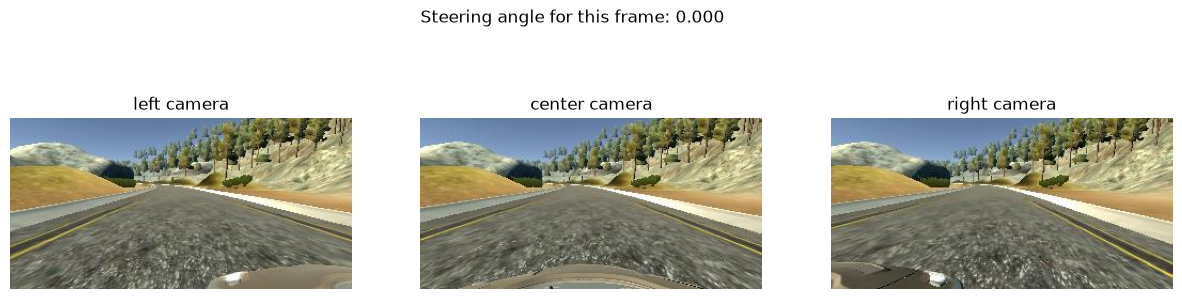

Image shape (height, width, channels): (160, 320, 3)


In [5]:
row = dataset.iloc[500]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, cam in zip(axs, ["left", "center", "right"]):
    img = mpimg.imread(os.path.join(datadir, "IMG", ntpath.split(row[cam])[1]))
    ax.imshow(img); ax.set_title(f"{cam} camera"); ax.axis("off")
plt.suptitle(f"Steering angle for this frame: {row['steering']:.3f}")
plt.show()
print("Image shape (height, width, channels):", img.shape)

## Summary
* The task is **regression**: image -> steering angle.
* The dataset has 7,259 logged moments, each with 3 images.
* The steering distribution is heavily concentrated near 0 - next week we analyse and fix that.